## Task 1

### 1.1 Bitcoin wallet exploit (3 point): Calculate the probability of generating an already used private key in the Bitcoin network, given that a total of 10^8 keys are in use. Give the formula and numerical results

Решение: приватный ключ k принимает значения:1≤k≤n−1, в случае secp256k1 n=1,158*10^77.
Тогда вероятность коллизии P=число ключей сгенерированных/общее число всевозможных ключей= 10^8/(1,158*10^(77))=8,6*10^(-70)

### 1.2 Verify your result experimentally on scaled-down versions of secp256k1. Here b denotes the bit length of the group order n, so n ≈ 2^b. The real secp256k1 has b = 256. For b = 20, 24, …, 40, find a prime p such that y² = x³ + 7 over F_p has a prime number of points n with b bits. Choose a population size N < n, measure how often a newly generated key matches one of the N existing ones, and compare with your formula. Plot log₂P against b and extrapolate to b = 256.

Решение: 1) посчитано в SageMath с кодом ниже

In [22]:
import random
import math
import matplotlib.pyplot as plt
import random
import string
import time
from typing import Callable, Iterable, List, Tuple, Optional
import pandas as pd
from tqdm import tqdm
import json
import hashlib
from copy import deepcopy
from dataclasses import dataclass

In [ ]:
def find_curve(b):
    t0 = time.time()
    for p in primes(2**(b-1), 2**b):
        E = EllipticCurve(GF(p), [0, 7])
        n = int(E.cardinality())
        if is_prime(n) and 2**(b-1) <= n < 2**b:
            return int(p), int(n)
    return None, None

results = {}
for b in [20, 24, 28, 32, 36, 40]:
    p, n = find_curve(b)
    results[b] = (p, n)
    print(b, p, n)

In [2]:
CURVES = {
    20: (526069, 527203),
    24: (8390323, 8394151),
    28: (134218291, 134227243),
    32: (2147485357, 2147548159),
    36: (34359740263, 34359753217),
    40: (549755814397, 549756995083),
}

In [6]:
def experiment(b, N, trials):
    p, n = CURVES[b]
    existing = set(random.randint(1, n - 1) for _ in range(N))
    matches = 0
    for _ in range(trials):
        if random.randint(1, n - 1) in existing:
            matches += 1
    return matches / trials, N / n

N = 500000

print(f"{'b':>3}  {'P_exp':>11}  {'P_theor':>11}  {'log2P_exp':>10}  {'log2P_theor':>11}")

results = []
for b in [20, 24, 28, 32, 36, 40]:
    trials = 200_000 if b <= 32 else 2_000_000
    P_exp, P_theor = experiment(b, N, trials)
    log2P_exp   = math.log2(P_exp)   if P_exp > 0 else None
    log2P_theor = math.log2(P_theor)
    results.append((b, P_exp, P_theor, log2P_exp, log2P_theor))
    print(f"{b:>3}  {P_exp:>11.2e}  {P_theor:>11.2e} {log2P_exp:>10.2f} {log2P_theor:>11.2f}")

  b        P_exp      P_theor   log2P_exp  log2P_theor
 20     6.12e-01     9.48e-01      -0.71       -0.08
 24     5.79e-02     5.96e-02      -4.11       -4.07
 28     3.52e-03     3.73e-03      -8.15       -8.07
 32     2.55e-04     2.33e-04     -11.94      -12.07
 36     1.75e-05     1.46e-05     -15.80      -16.07
 40     5.00e-07     9.09e-07     -20.93      -20.07


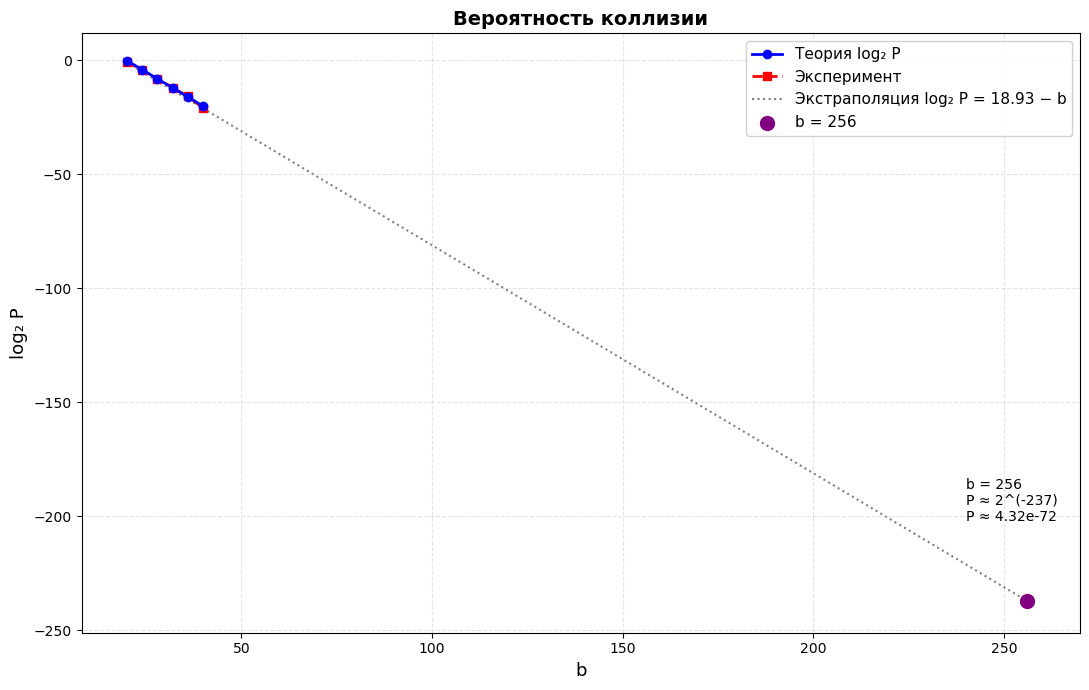

In [10]:
bs           = [r[0] for r in results]
log2P_exp    = [r[3] for r in results]
log2P_theor  = [r[4] for r in results]

bs_exp_plot       = [b for b, l in zip(bs, log2P_exp) if l is not None]
log2P_exp_plot    = [l for l in log2P_exp if l is not None]

log2N = math.log2(N)
b_extrap     = list(range(20, 260, 2))
log2P_extrap = [log2N - b for b in b_extrap]

b_target     = 256
log2P_target = log2N - b_target

plt.figure(figsize=(11, 7))

plt.plot(bs, log2P_theor, 'o-', color='blue', markersize=6,
         linewidth=2, label='Теория log₂ P', zorder=3)

if bs_exp_plot:
    plt.plot(bs_exp_plot, log2P_exp_plot, 's--', color='red', markersize=6,
             linewidth=2, label='Эксперимент', zorder=2)

plt.plot(b_extrap, log2P_extrap, ':', color='gray', linewidth=1.5,
         label=f'Экстраполяция log₂ P = {log2N:.2f} − b', zorder=1)

plt.scatter([b_target], [log2P_target], color='purple', s=100,
            zorder=5, label=f'b = 256')
plt.annotate(
    f'b = 256\n'
    f'P ≈ 2^({log2P_target:.0f})\n'
    f'P ≈ {2**log2P_target:.2e}',
    xy=(b_target, log2P_target),
    xytext=(240, log2P_target + 35),
)

plt.xlabel('b', fontsize=13)
plt.ylabel('log₂ P', fontsize=13)
plt.title('Вероятность коллизии', fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.35, linestyle='--')
plt.legend(loc='upper right', fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.show()


## Task 2

Implement your own hash function in Python (3 points):
Demonstrate the properties of a hash function on your input data:
determinism
computation speed
avalanche effect
uniformity
chi sqaured
collisions
bit balances
Describe the advantages and disadvantages of your hash function based on benchmark results

In [20]:
def custom_mix_hash(data: str | bytes, bits: int = 256, as_hex: bool = True) -> str | int:
    if isinstance(data, str):
        data = data.encode("utf-8")

    mask = (1 << bits) - 1
    
    C1 = 0x9e3779b97f4a7c159e3779b97f4a7c159e3779b97f4a7c159e3779b97f4a7c15
    C2 = 0xbf58476d1ce4e5b9bf58476d1ce4e5b9bf58476d1ce4e5b9bf58476d1ce4e5b9
    
    h = 0xcbf29ce484222325cbf29ce484222325cbf29ce484222325cbf29ce484222325
    
    data = data + b'\x00' * ((4 - len(data) % 4) % 4)
    
    for i in range(0, len(data), 4):
        chunk = int.from_bytes(data[i:i+4], byteorder='little')
        h ^= chunk
        h = (h * C1) & mask
        h = ((h << 7) | (h >> (bits - 7))) & mask
        
    h ^= (h >> 16)
    h = (h * C2) & mask
    h ^= (h >> 24)
    h = (h * C1) & mask
    h ^= (h >> (bits // 2))
    
    return h if not as_hex else f"{h:0{bits//4}x}"


def hash_hex(name: str, data: str) -> str:
    data = data.encode("utf-8")
    if name == "mix_hash":
        return custom_mix_hash(data, bits=256, as_hex=True)
    
    if name == "sha256": return hashlib.sha256(data).hexdigest()
    if name == "sha1": return hashlib.sha1(data).hexdigest()

def hex_to_int(h: str) -> int:
    return int(h, 16)

def random_ascii_string(length: int) -> str:
    return "".join(random.choices(string.ascii_letters + string.digits, k=length))

def flip_one_bit_in_text(s: str) -> str:
    """Переворачивает один случайный бит в строке. Используем latin-1, чтобы избежать ошибок декодирования UTF-8."""
    b = bytearray(s.encode("latin-1"))
    byte_idx = random.randint(0, len(b) - 1)
    bit_idx = random.randint(0, 7)
    b[byte_idx] ^= (1 << bit_idx)
    return b.decode("latin-1")

def hamming_distance(h1: int, h2: int) -> int:
    return bin(h1 ^ h2).count('1')


#Benchmark
def test_determinism(name: str = "mix_hash", trials: int = 1000):
    s = "determinism_test_string_12345!@#"
    hashes = {hash_hex(name, s) for _ in range(trials)}
    is_deterministic = len(hashes) == 1
    print(f"[Determinism] {name}: {'PASS' if is_deterministic else 'FAIL'} (Unique hashes: {len(hashes)})")
    return is_deterministic

def measure_time(func: Callable[[], None], repeats: int = 3) -> float:
    best = float('inf')
    for _ in range(repeats):
        t0 = time.perf_counter()
        func()
        best = min(best, time.perf_counter() - t0)
    return best

def benchmark_speed(names=("mix_hash", "sha256", "sha1"), sizes=[10, 100, 1000, 5000], n_per_size=500):
    rows = []
    samples = {L: [random_ascii_string(L) for _ in range(n_per_size)] for L in sizes}
    for name in tqdm(names, desc="Speed Benchmark"):
        for L in sizes:
            strings = samples[L]
            def run():
                acc = 0
                for s in strings:
                    acc ^= hex_to_int(hash_hex(name, s))
                return acc
            elapsed = measure_time(run, repeats=3)
            total_bytes = n_per_size * L
            ns_per_byte = (elapsed / total_bytes) * 1e9 if elapsed > 0 else 0
            mbps = (total_bytes / elapsed) / (1024 * 1024) if elapsed > 0 else 0
            rows.append((name, L, ns_per_byte, mbps, elapsed))
    return pd.DataFrame(rows, columns=["hash","size_bytes","ns_per_byte","MB_per_s", "elapsed"])

def plot_speed(df: pd.DataFrame):
    plt.figure(figsize=(10, 5))
    for name, sub in df.groupby("hash"):
        sub = sub.sort_values("size_bytes")
        plt.plot(sub["size_bytes"], sub["MB_per_s"], marker="o", label=name)
    plt.xlabel("Input size (bytes)"); plt.ylabel("MB/s")
    plt.title("Speed: throughput vs input size"); plt.legend(); plt.grid(True)
    plt.show()

def test_avalanche(names=("mix_hash", "sha256"), input_len: int = 64, samples: int = 5000):
    rows = []
    for name in names:
        bits = len(hash_hex(name, "")) * 4
        total_flipped = 0
        for _ in range(samples):
            s = random_ascii_string(input_len)
            s_flipped = flip_one_bit_in_text(s)
            h1 = hex_to_int(hash_hex(name, s))
            h2 = hex_to_int(hash_hex(name, s_flipped))
            total_flipped += hamming_distance(h1, h2)
        avg = total_flipped / samples
        ideal = bits / 2.0
        rows.append((name, bits, avg, ideal, avg/ideal))
    return pd.DataFrame(rows, columns=["hash", "bits", "avg_flipped", "ideal", "ratio"])

def plot_avalanche(df: pd.DataFrame):
    plt.figure(figsize=(8, 5))
    plt.bar(df["hash"], df["ratio"], color=['orange', 'blue', 'green'])
    plt.axhline(1.0, color='red', linestyle='--', label='Ideal (50%)')
    plt.ylabel("Ratio (avg_flipped / ideal)")
    plt.title("Avalanche Effect (Closer to 1.0 is better)"); plt.legend(); plt.grid(True, axis='y')
    plt.show()

def chi_square_uniformity(names=("mix_hash", "sha256"), out_bits: int = 64, bucket_bits: int = 10, N: int = 100_000):
    B = 1 << bucket_bits
    expected = N / B
    rows = []
    samples = [random_ascii_string(32) for _ in range(N)]
    for name in names:
        counts = [0] * B
        for s in samples:
            h = hex_to_int(hash_hex(name, s))
            # Берем младшие биты для распределения по бакетам
            counts[h & (B - 1)] += 1
        chi2 = sum(((c - expected) ** 2) / expected for c in counts)
        rows.append((name, B, N, chi2))
    return pd.DataFrame(rows, columns=["hash","buckets","samples","chi2"])

def plot_uniformity(df: pd.DataFrame):
    B = int(df["buckets"].iloc[0]); N = int(df["samples"].iloc[0]); dof = B - 1
    df["chi2_per_df"] = df["chi2"] / dof
    sd_norm = math.sqrt(2.0 / dof)
    band_lo, band_hi = 1 - 2 * sd_norm, 1 + 2 * sd_norm
    
    plt.figure(figsize=(8, 5))
    plt.bar(df["hash"], df["chi2_per_df"])
    plt.axhline(1.0, linestyle="--", color='green', label='Ideal (1.0)')
    plt.fill_between([-0.5, len(df)-0.5], band_lo, band_hi, alpha=0.2, color='gray', label='±2σ band')
    plt.ylabel("χ² / dof"); plt.title("Uniformity (Chi-Squared)"); plt.legend(); plt.grid(True, axis='y')
    plt.show()

def collision_test(names=("mix_hash", "sha256"), out_bits: int = 32, N: int = 100_000):
    rows = []
    samples = [random_ascii_string(32) for _ in range(N)]
    for name in names:
        seen = set()
        collisions = 0
        for s in samples:
            h = hex_to_int(hash_hex(name, s)) & ((1 << out_bits) - 1)
            if h in seen: collisions += 1
            else: seen.add(h)
        expected = (N * (N - 1)) / (2 * (1 << out_bits))
        rows.append((name, out_bits, N, collisions, expected))
    return pd.DataFrame(rows, columns=["hash","bits","N","collisions","expected"])

def plot_collisions(df: pd.DataFrame):
    plt.figure(figsize=(8, 5))
    plt.bar(df["hash"], df["collisions"])
    plt.axhline(df["expected"].iloc[0], linestyle="--", color='red', label=f'Expected ({df["expected"].iloc[0]:.1f})')
    plt.ylabel("Observed collisions"); plt.title("Collisions under truncation (32 bits)"); plt.legend(); plt.grid(True, axis='y')
    plt.show()

def bit_balance(names=("mix_hash", "sha256"), out_bits: int = 64, N: int = 50_000):
    rows = []
    samples = [random_ascii_string(48) for _ in range(N)]
    for name in names:
        ones = [0] * out_bits
        for s in samples:
            h = hex_to_int(hash_hex(name, s))
            for b in range(out_bits):
                ones[b] += (h >> b) & 1
        freqs = [x / N for x in ones]
        avg_dev = sum(abs(f - 0.5) for f in freqs) / out_bits
        rows.append((name, out_bits, N, avg_dev))
    return pd.DataFrame(rows, columns=["hash","bits","N","avg_abs_dev"])

def plot_bit_balance(df: pd.DataFrame):
    plt.figure(figsize=(8, 5))
    plt.bar(df["hash"], df["avg_abs_dev"])
    plt.ylabel("Avg |p(bit=1) - 0.5| (lower is better)")
    plt.title("Bit balance"); plt.grid(True, axis='y')
    plt.show()


Determinism
[Determinism] mix_hash: PASS (Unique hashes: 1)
[Determinism] sha256: PASS (Unique hashes: 1)
Speed


Speed Benchmark: 100%|██████████| 2/2 [00:10<00:00,  5.22s/it]


       hash  size_bytes    MB_per_s
0  mix_hash          10    0.839199
1  mix_hash         100    2.060479
2  mix_hash        1000    2.189927
3  mix_hash        5000    2.083956
4    sha256          10    2.439314
5    sha256         100   23.831729
6    sha256        1000  103.590441
7    sha256        5000  143.942584


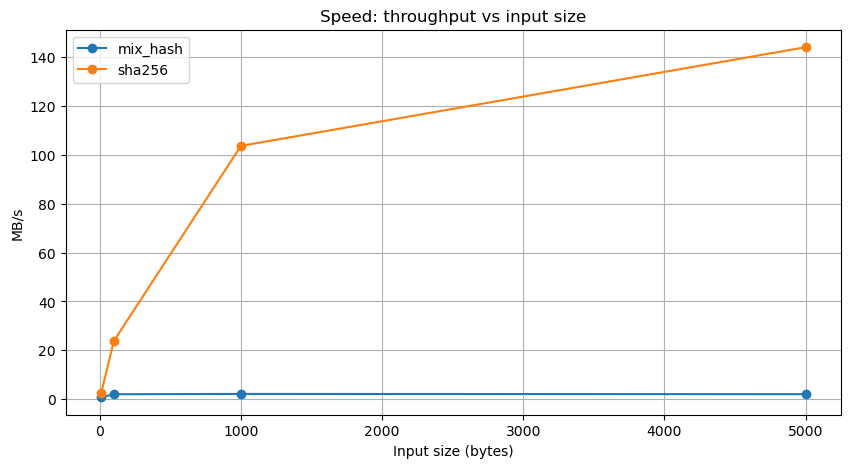

Avalanche Effect
       hash  bits  avg_flipped  ideal     ratio
0  mix_hash   256     128.0150  128.0  1.000117
1    sha256   256     128.0734  128.0  1.000573


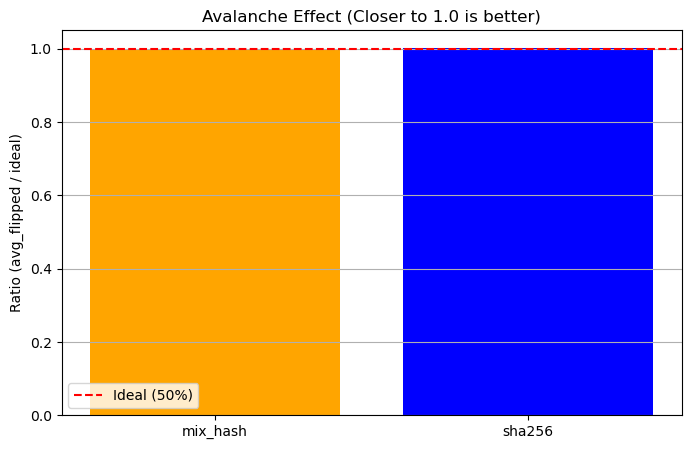

Uniformity (Chi-Squared)
       hash  buckets  samples        chi2
0  mix_hash     1024   100000   948.84864
1    sha256     1024   100000  1039.18592


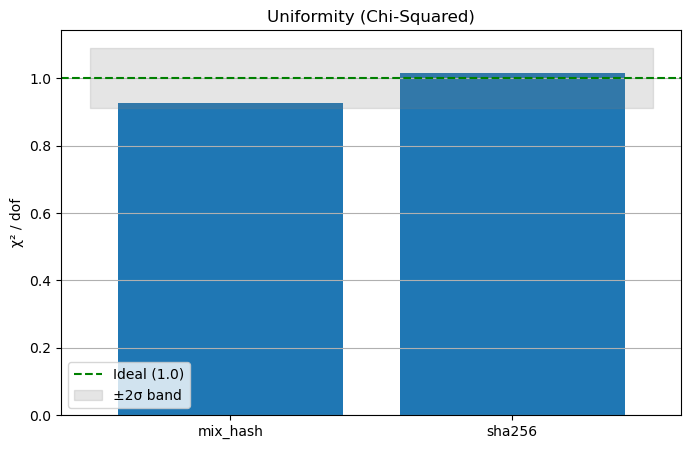

Collisions
       hash  bits       N  collisions  expected
0  mix_hash    32  100000           2  1.164142
1    sha256    32  100000           1  1.164142


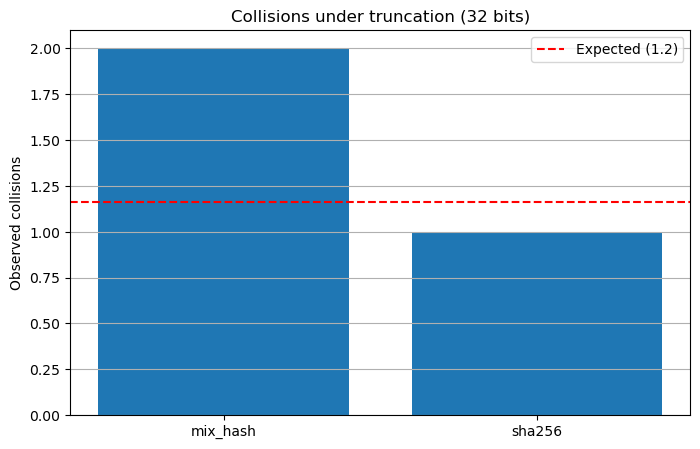

Bit Balance
       hash  bits      N  avg_abs_dev
0  mix_hash    64  50000     0.001553
1    sha256    64  50000     0.001677


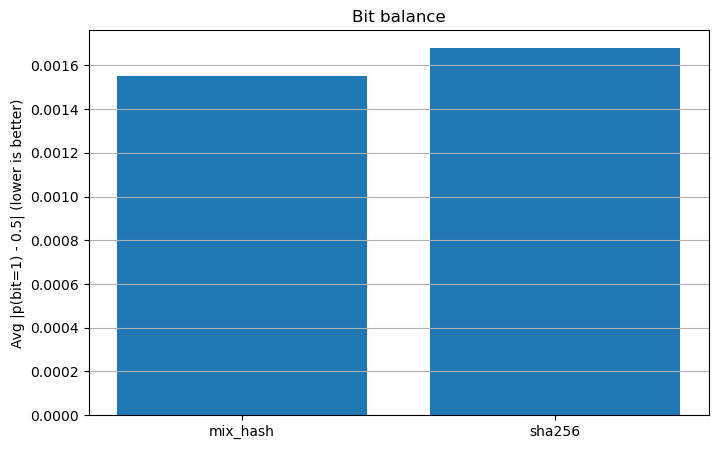

In [19]:
print("Determinism")
test_determinism("mix_hash")
test_determinism("sha256")
print("Speed")
df_speed = benchmark_speed(names=("mix_hash", "sha256"), sizes=[10, 100, 1000, 5000], n_per_size=1000)
print(df_speed[["hash", "size_bytes", "MB_per_s"]])
plot_speed(df_speed)
print("Avalanche Effect")
df_av = test_avalanche(names=("mix_hash", "sha256"), input_len=64, samples=5000)
print(df_av)
plot_avalanche(df_av)
print("Uniformity (Chi-Squared)")
df_chi = chi_square_uniformity(names=("mix_hash", "sha256"), out_bits=64, bucket_bits=10, N=100_000)
print(df_chi)
plot_uniformity(df_chi)
print("Collisions")
df_col = collision_test(names=("mix_hash", "sha256"), out_bits=32, N=100_000)
print(df_col)
plot_collisions(df_col)
print("Bit Balance")
df_bb = bit_balance(names=("mix_hash", "sha256"), out_bits=64, N=50_000)
print(df_bb)
plot_bit_balance(df_bb)

## Task 3

Based on the MerkleTree example from the seminar, implement (4 points):
a method to generate a Merkle Proof
a method to verify whether a transaction is included in the merkle tree using the Merkle tree.
The full Merkle Proof for `tx2` consists of:
The sibling hash at the first level: h(tx1)
The hash from the second level: h(tx3, tx4)

In [ ]:
def calculate_sha256(data: str) -> str:
    return hashlib.sha256(data.encode('utf-8')).hexdigest()


class Transaction:
    def __init__(self, tx_id: int, amount: float, message: str):
        self._tx_id: int = tx_id
        self._amount: float = amount
        self._message: str = message

    def json(self) -> str:
        data: dict = {
            'tx_id': self._tx_id,
            'amount': self._amount,
            'message': self._message
        }
        return json.dumps(data, sort_keys=True)

    def __repr__(self) -> str:
        return self.json()


@dataclass
class MerkleNode:
    left: Optional["MerkleNode"]
    right: Optional["MerkleNode"]
    hash_value: str


class MerkleTree:
    def __init__(self, transactions: List[Transaction]):
        self._leaves: List[MerkleNode] = [
            MerkleNode(None, None, calculate_sha256(it.json())) 
            for it in transactions
        ]
        self._root: Optional[MerkleNode] = self._build()

    def _build(self) -> Optional[MerkleNode]:
        if not self._leaves:
            return None
        level: List[MerkleNode] = self._leaves
        while len(level) > 1:
            next_level: List[MerkleNode] = []
            # Если нечетное количество, дублируем последний узел
            if len(level) % 2 == 1:
                level = level + [level[-1]]
            
            for i in range(0, len(level), 2):
                left = level[i]
                right = level[i + 1]
                parent_hash = calculate_sha256(left.hash_value + right.hash_value)
                next_level.append(MerkleNode(left, right, parent_hash))
            level = next_level
        return level[0]

    @property
    def root(self) -> Optional[MerkleNode]:
        return self._root

    def merkle_root_hex(self) -> Optional[str]:
        return self._root.hash_value if self._root else None

    def generate_proof(self, tx: Transaction) -> Optional[List[Tuple[str, str]]]:
        target_hash = calculate_sha256(tx.json())
        
        def _find_path(node: MerkleNode, target: str) -> Optional[List[Tuple[str, str]]]:
            if node is None:
                return None
            
            if node.left is None and node.right is None:
                if node.hash_value == target:
                    return [] 
                return None
            
            left_proof = _find_path(node.left, target)
            if left_proof is not None:
                left_proof.append((node.right.hash_value, 'right'))
                return left_proof
            
            right_proof = _find_path(node.right, target)
            if right_proof is not None:
                right_proof.append((node.left.hash_value, 'left'))
                return right_proof
            
            return None

        proof = _find_path(self._root, target_hash)
        
        return proof


    @staticmethod
    def verify_proof(tx: Transaction, proof: List[Tuple[str, str]], root_hash: str) -> bool:
        current_hash = calculate_sha256(tx.json())
        
        for sibling_hash, position in proof:
            if position == 'left':
                current_hash = calculate_sha256(sibling_hash + current_hash)
            elif position == 'right':
                current_hash = calculate_sha256(current_hash + sibling_hash)
            else:
                raise ValueError("Некорректная позиция в доказательстве")
                
        return current_hash == root_hash

In [31]:
tx1 = Transaction(1, 1.0, "Payment A")
tx2 = Transaction(2, 20.0, "Payment B")
tx3 = Transaction(3, 30.0, "Payment C")
tx4 = Transaction(4, 40.0, "Payment D")
tx5 = Transaction(5, 50.0, "Payment E")
tx6 = Transaction(6, 60.0, "Payment F")
transactions = [tx1, tx2, tx3, tx4, tx5, tx6]
tree = MerkleTree(transactions)

root = tree.merkle_root_hex()
print(f"Merkle Root: {root}\n")
print("Доказательство для tx2")
proof = tree.generate_proof(tx2)

if proof:
    for i, (sibling_hash, pos) in enumerate(proof):
        print(f"Уровень {i+1}: соседний хэш = {sibling_hash}, {pos}")
else:
    print("Транзакция не найдена!")

print("Верификация без подмены")
is_valid = MerkleTree.verify_proof(tx2, proof, root)
print(is_valid)

print("Верификация с подменой")
fake_tx = Transaction(2, 999.0, "hacked") 
is_valid_fake = MerkleTree.verify_proof(fake_tx, proof, root)
print(is_valid_fake)

Merkle Root: 5b0f988a1ca531ed2fbd6060261c7e0049820a6d1ce4ae704afe5fe90b24633d

Доказательство для tx2
Уровень 1: соседний хэш = b84c0f3c71cc7291d568d6ef4a722b4d8fd1f66cf294f05190e0d337ecceff80, left
Уровень 2: соседний хэш = e471e7afb55ba297b87f7390d9e92f94ae39b76527db1658cee19cf55aec674a, right
Уровень 3: соседний хэш = ac0b3978927a5a705ffea1be84ab757c699c3212d23ee9bbf799b98c54e24750, right
Верификация без подмены
True
Верификация с подменой
False
